<a href="https://colab.research.google.com/github/PreethiR091/Deep-Learning/blob/main/Preethi_R_24BAD091_DL_Ex_no_6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART A: DATASET PREPARATION

Perform the following tasks:

    •	Load a suitable sentiment analysis dataset such as the IMDB Movie Reviews dataset.
    •	Explore the dataset and examine sample reviews and their corresponding sentiment labels.
    •	Identify the positive and negative sentiment classes.
    •	Perform basic text preprocessing such as converting text to lowercase, if required.
    •	Remove unnecessary characters or symbols, if required.
    •	Tokenize the reviews into words.
    •	Build a vocabulary and assign unique integer indices to words.
    •	Convert the text reviews into numerical sequences.
    •	Apply sequence padding to obtain inputs of equal length.
    •	Split the prepared dataset into training and validation/testing datasets.


In [6]:

# Experiment 6 - Part A: Dataset Preparation
# Name: Preethi R
# Register Number: 24BAD091

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import seaborn as sns

print("Preethi R 24BAD091")
print("TensorFlow Version:", tf.__version__)

vocab_size = 10000
max_length = 200

(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

word_index = imdb.get_word_index()

print("Training samples:", len(x_train_full))
print("Testing samples:", len(x_test))
print("Vocabulary size:", len(word_index))
print("Sentiment labels: 0 = Negative, 1 = Positive")

# Decode a sample review
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

sample_review = " ".join(
    reverse_word_index.get(i, "?") for i in x_train_full[0]
)

print("\nSample Review:")
print(sample_review[:500])
print("Sentiment:", "Positive" if y_train_full[0] == 1 else "Negative")

# Pad sequences to equal length
x_train_full = pad_sequences(
    x_train_full, maxlen=max_length, padding="post", truncating="post"
)

x_test = pad_sequences(
    x_test, maxlen=max_length, padding="post", truncating="post"
)

# Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.2, random_state=42, stratify=y_train_full
)

print("\nTraining data shape:", x_train.shape)
print("Validation data shape:", x_val.shape)
print("Testing data shape:", x_test.shape)
print("Dataset preparation completed.")


Preethi R 24BAD091
TensorFlow Version: 2.21.0
Training samples: 25000
Testing samples: 25000
Vocabulary size: 88584
Sentiment labels: 0 = Negative, 1 = Positive

Sample Review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would re
Sentiment: Positive

Training data shape: (20000, 200)
Validation data shape: (5000, 200)
Testing data shape: (25000, 200)
Dataset preparation completed.


PART B: IMPLEMENTING THE LSTM MODEL

Perform the following tasks:

    •	Create an Embedding layer to convert words into dense vector representations.
    •	Add an LSTM layer to learn long-term sequential dependencies in the reviews.
    •	Add a Dense output layer for sentiment classification.
    •	Use an appropriate activation function such as Sigmoid for binary sentiment classification.
    •	Compile the model using an appropriate optimizer and loss function.
    •	Display the model architecture and model summary.


In [9]:

# Part B: LSTM Model
# Name: Preethi R
# Register Number: 24BAD091

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

vocab_size = 10000
max_length = 200

model = Sequential([
    Input(shape=(max_length,)),
    Embedding(input_dim=vocab_size, output_dim=64),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Preethi R  24BAD091")
model.summary()


Preethi R  24BAD091


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

Perform the following tasks:

    •	Train the LSTM model using the prepared training dataset.
    •	Validate the model using the validation dataset.
    •	Record:
        o	Training accuracy
        o	Validation accuracy
        o	Training loss
        o	Validation loss
    •	Evaluate the trained model on the test dataset.
    •	Calculate suitable evaluation metrics such as:
        o	Accuracy
        o	Precision
        o	Recall
        o	F1-score
    •	Generate a confusion matrix to analyze the classification performance.
    •	Visualize:
        o	Accuracy vs. Epoch
        o	Loss vs. Epoch


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 359ms/step - accuracy: 0.5130 - loss: 0.6936 - val_accuracy: 0.4978 - val_loss: 0.6913
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 354ms/step - accuracy: 0.5810 - loss: 0.6773 - val_accuracy: 0.6272 - val_loss: 0.6566
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 351ms/step - accuracy: 0.6305 - loss: 0.6503 - val_accuracy: 0.5390 - val_loss: 0.6817
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 358ms/step - accuracy: 0.5755 - loss: 0.6657 - val_accuracy: 0.5816 - val_loss: 0.6683
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 354ms/step - accuracy: 0.6279 - loss: 0.6469 - val_accuracy: 0.5060 - val_loss: 0.6911
Model training completed.
Preethi R 24BAD091

Test Loss: 0.6896
Test Accuracy: 0.5047
Precision: 0.5757
Recall: 0.0356
F1-Score: 0.0671

Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      0.97      0.66     12500
    Positive       0.58      0.04      0.07     12500

    accuracy              

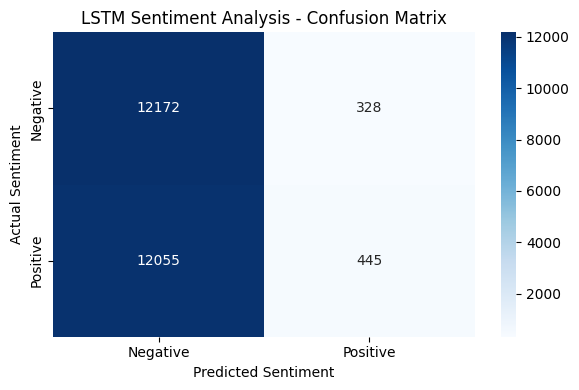

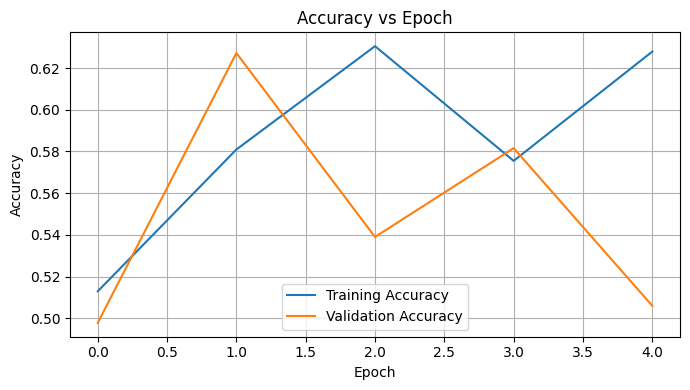

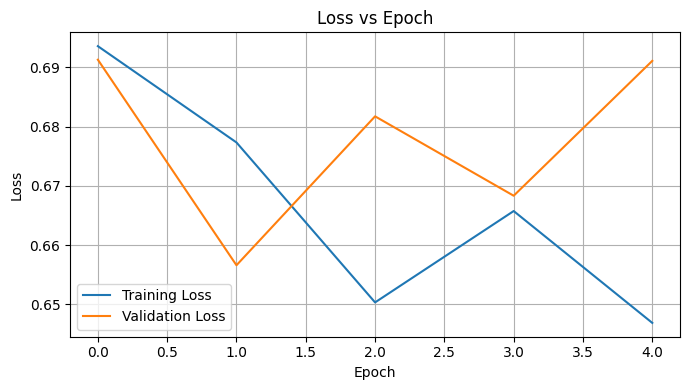

In [10]:
# Part C: Model Training and performance evaluation
# Name : Preethi R
# Register Number: 24BAD091

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val),
    verbose=1
)

print("Model training completed.")


# Model Evaluation
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

y_prob = model.predict(x_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Preethi R 24BAD091")
print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))


# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.tight_layout()
plt.show()


# Accuracy and Loss Graphs

plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



PART D: SENTIMENT PREDICTION AND DEEP LEARNING EXPERIMENT MANAGEMENT

Perform the following tasks:

    •	Provide new movie-review sentences as input to the trained LSTM model.
    •	Preprocess and tokenize the input text using the same vocabulary used during training.
    •	Apply sequence padding to the input text.
    •	Predict the sentiment using the trained LSTM model.
    •	Classify the input as Positive or Negative based on the predicted probability.
    •	Provide multiple review samples with different sentiments.
    •	Compare the predicted sentiment with the actual/expected sentiment.
    •	Analyze the coherence and correctness of the model predictions.
    •	Document the observations and upload the notebook to GitHub.


In [11]:

# Part D: Sentiment Prediction
# Name : Preethi R
# Register Number: 24BAD091

def preprocess_review(review):
    words = review.lower().split()
    sequence = []

    for word in words:
        index = word_index.get(word, 2) + 3

        if index >= vocab_size + 3:
            index = 2

        sequence.append(index)

    return pad_sequences(
        [sequence], maxlen=max_length,
        padding="post", truncating="post"
    )

reviews = [
    ("This movie was amazing and wonderful", "Positive"),
    ("The film was boring and disappointing", "Negative"),
    ("I really enjoyed the excellent acting", "Positive"),
    ("The story was terrible and very slow", "Negative"),
    ("It was not good and I hated it", "Negative"),
    ("A fantastic movie with a great story", "Positive")
]

print("Preethi R 24BAD091")
print("\nSentiment Predictions:\n")

for review, expected in reviews:
    processed_review = preprocess_review(review)
    probability = model.predict(processed_review, verbose=0)[0][0]

    predicted = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Expected Sentiment:", expected)
    print("Predicted Sentiment:", predicted)
    print("Positive Probability:", round(float(probability), 4))
    print("-" * 50)


# Save the trained model

model.save("LSTM_Sentiment_24BAD091.keras")

print("Model saved successfully.")



Preethi R 24BAD091

Sentiment Predictions:

Review: This movie was amazing and wonderful
Expected Sentiment: Positive
Predicted Sentiment: Negative
Positive Probability: 0.4747
--------------------------------------------------
Review: The film was boring and disappointing
Expected Sentiment: Negative
Predicted Sentiment: Negative
Positive Probability: 0.4747
--------------------------------------------------
Review: I really enjoyed the excellent acting
Expected Sentiment: Positive
Predicted Sentiment: Negative
Positive Probability: 0.4747
--------------------------------------------------
Review: The story was terrible and very slow
Expected Sentiment: Negative
Predicted Sentiment: Negative
Positive Probability: 0.4747
--------------------------------------------------
Review: It was not good and I hated it
Expected Sentiment: Negative
Predicted Sentiment: Negative
Positive Probability: 0.4747
--------------------------------------------------
Review: A fantastic movie with a great s